# Tuần 2: Encoding × Scaling × Mô hình hồi quy

Notebook chỉ **hiển thị kết quả** đã tính bởi `python -m src.experiments` (đọc từ `reports/tables/week2_*.csv`).
Đánh giá bằng GroupKFold 5 fold trên **tập train**; tập test không được dùng.
Báo cáo đầy đủ: `reports/week2_report.md`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format)
T, F = ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
meta = json.loads((ROOT / 'reports' / 'week2_run_meta.json').read_text(encoding='utf-8'))
print(meta)
res = pd.read_csv(T / 'week2_fold_results.csv')
print(res.shape, '| thí nghiệm:', res.experiment.value_counts().to_dict())

{'n_dev_rows': 20001, 'n_dev_groups': 19316, 'n_splits': 5, 'finished_at': '2026-11-05T20:45:05', 'n_result_rows': 560}
(560, 15) | thí nghiệm: {'main': 320, 'log_target': 80, 'model_version': 80, 'log_features': 80}


## 1. Cấu hình tốt nhất của từng mô hình (64 cấu hình, giá gốc)

In [2]:
best = pd.read_csv(T / 'week2_best_per_model.csv')
best[['model','encoder','scaler','mae_mean','mae_std','rmse_mean','r2_mean','medape_pct_mean','n_features_out','fit_seconds_mean']]

,model,encoder,scaler,mae_mean,mae_std,rmse_mean,r2_mean,medape_pct_mean,n_features_out,fit_seconds_mean
0,rf,onehot,standard,"7,369.14","1,000.74","44,435.56",0.76,8.84,282,178.41
1,svr,onehot,standard,"9,445.45","1,525.06","61,838.15",0.59,13.39,282,17.53
2,knn,onehot,standard,"9,621.97","1,675.18","59,461.10",0.60,11.63,282,0.31
3,ridge,onehot,minmax,"22,681.17","1,880.95","79,087.72",0.31,35.63,282,0.55


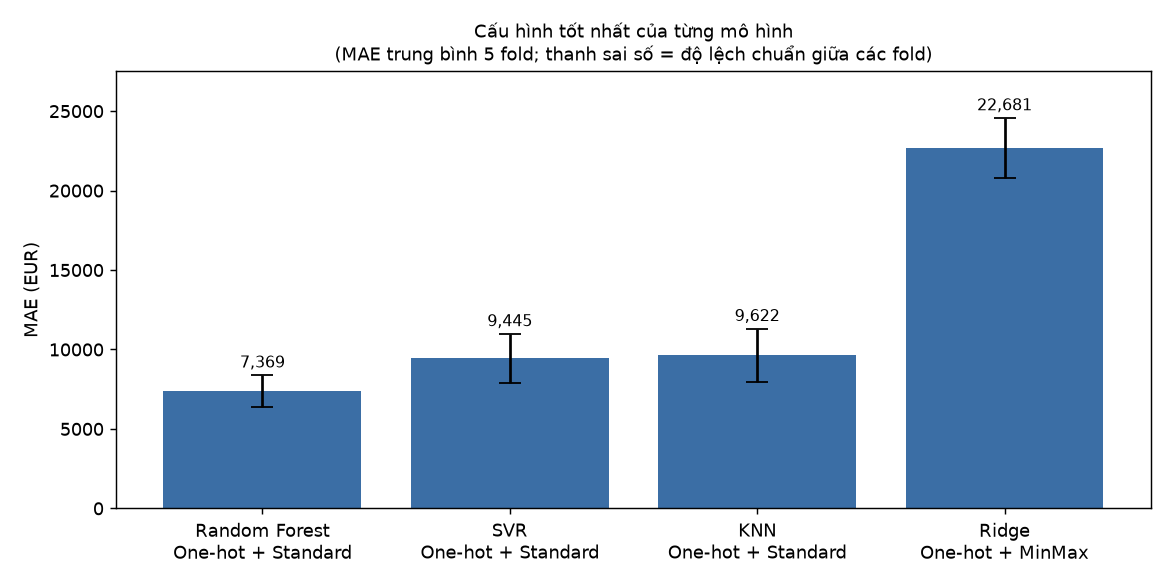

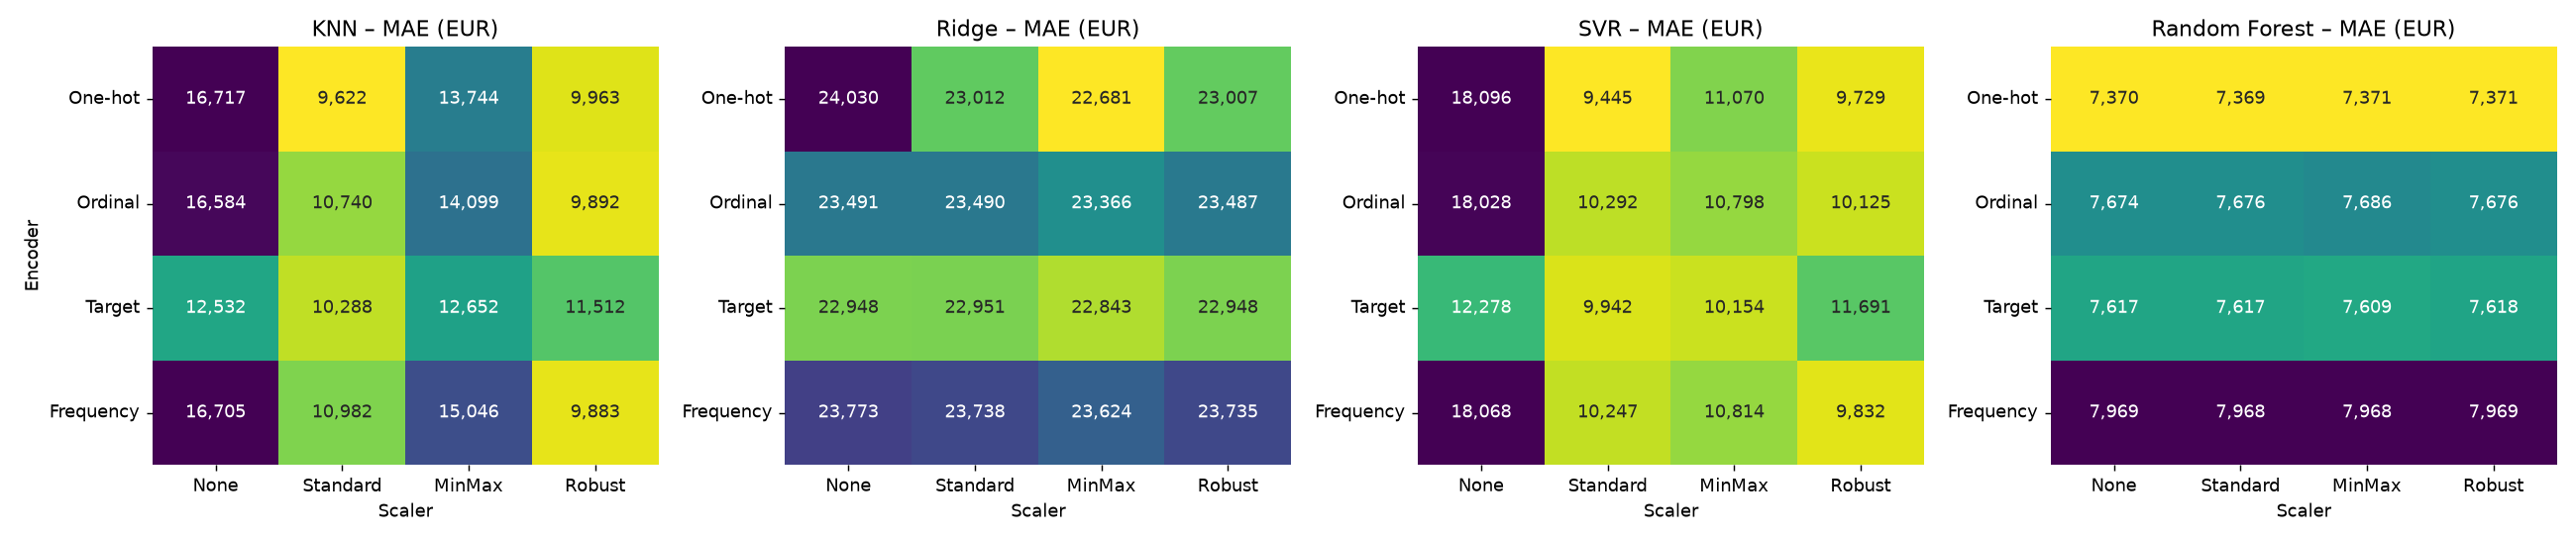

In [3]:
display(Image(str(F / 'week2_best_models.png')))
Image(str(F / 'week2_heatmap_mae.png'))

MAE trung bình 5 fold (EUR); màu sáng = tốt hơn. Random Forest gần như không đổi theo scaler; KNN và SVR cải thiện rất mạnh khi có scale.

## 2. Encoding: so sánh cặp theo fold với One-hot (scaler Standard)

In [4]:
pe = pd.read_csv(T / 'week2_paired_encoder_vs_onehot_standard.csv')
pe.sort_values(['model','level'])

,model,level,baseline,mean_diff,rel_change_pct,folds_better,n
8,knn,frequency,onehot,"1,359.73",14.13,0,5
0,knn,ordinal,onehot,"1,117.70",11.62,0,5
4,knn,target,onehot,665.85,6.92,0,5
9,rf,frequency,onehot,599.28,8.13,0,5
1,rf,ordinal,onehot,306.78,4.16,0,5
5,rf,target,onehot,248.30,3.37,1,5
10,ridge,frequency,onehot,725.90,3.15,2,5
2,ridge,ordinal,onehot,477.79,2.08,2,5
6,ridge,target,onehot,-60.95,-0.26,2,5
11,svr,frequency,onehot,801.08,8.48,0,5


`folds_better` = số fold (trên 5) mà encoder đó tốt hơn One-hot; `rel_change_pct` > 0 = tệ hơn One-hot.

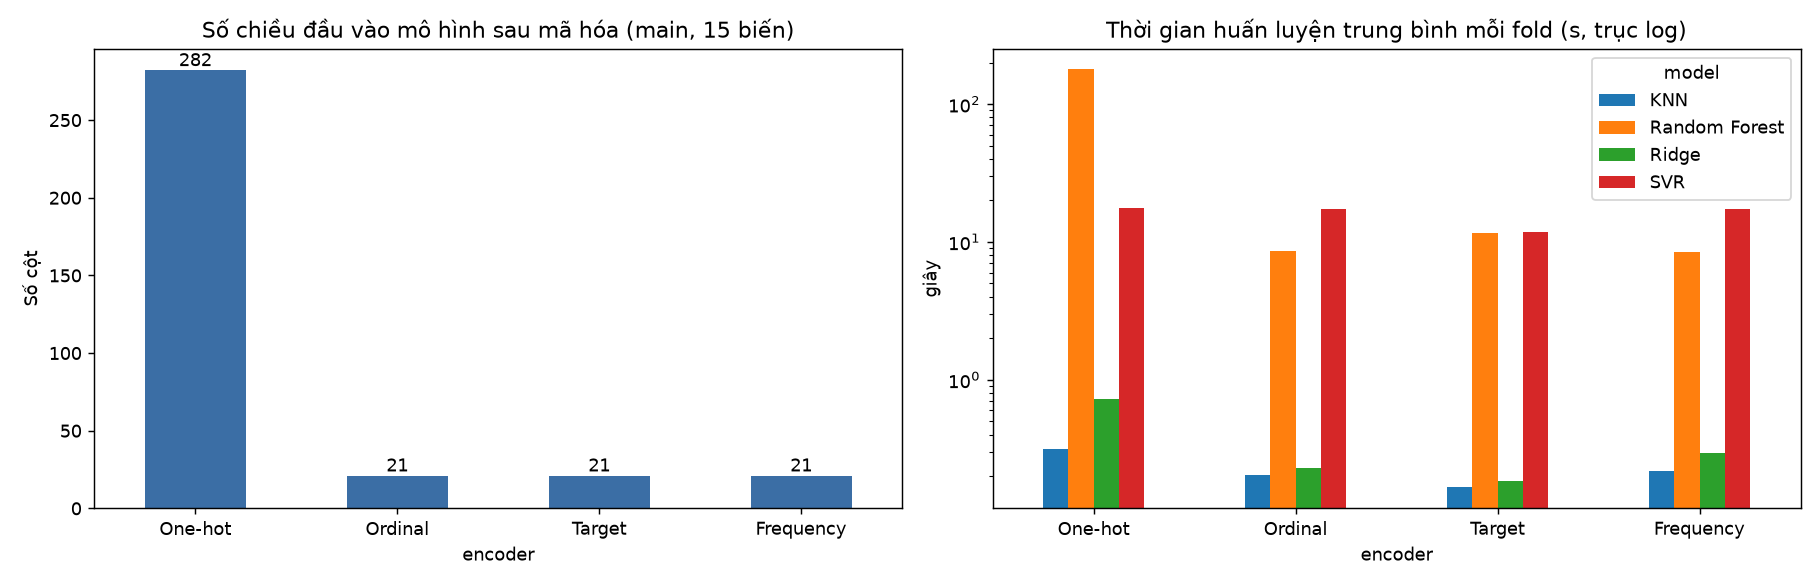

In [5]:
display(Image(str(F / 'week2_dims_time.png')))

## 3. Scaling: so sánh với No scaling

In [6]:
ps = pd.read_csv(T / 'week2_paired_scaler_vs_none.csv')
ps.groupby(['model','level']).agg(delta_mae_pct=('rel_change_pct','mean'), folds_better=('folds_better','sum'), n=('n','sum'))

delta_mae_pct  folds_better   n
model level                                    
knn   minmax           -11.19            18  20
      robust           -34.04            20  20
      standard         -33.43            20  20
rf    minmax             0.01            12  20
      robust             0.01             9  20
      standard           0.00             9  20
ridge minmax            -1.83            15  20
      robust            -1.13            15  20
      standard          -1.12            14  20
svr   minmax           -35.55            20  20
      robust           -37.75            18  20
      standard         -39.93            20  20

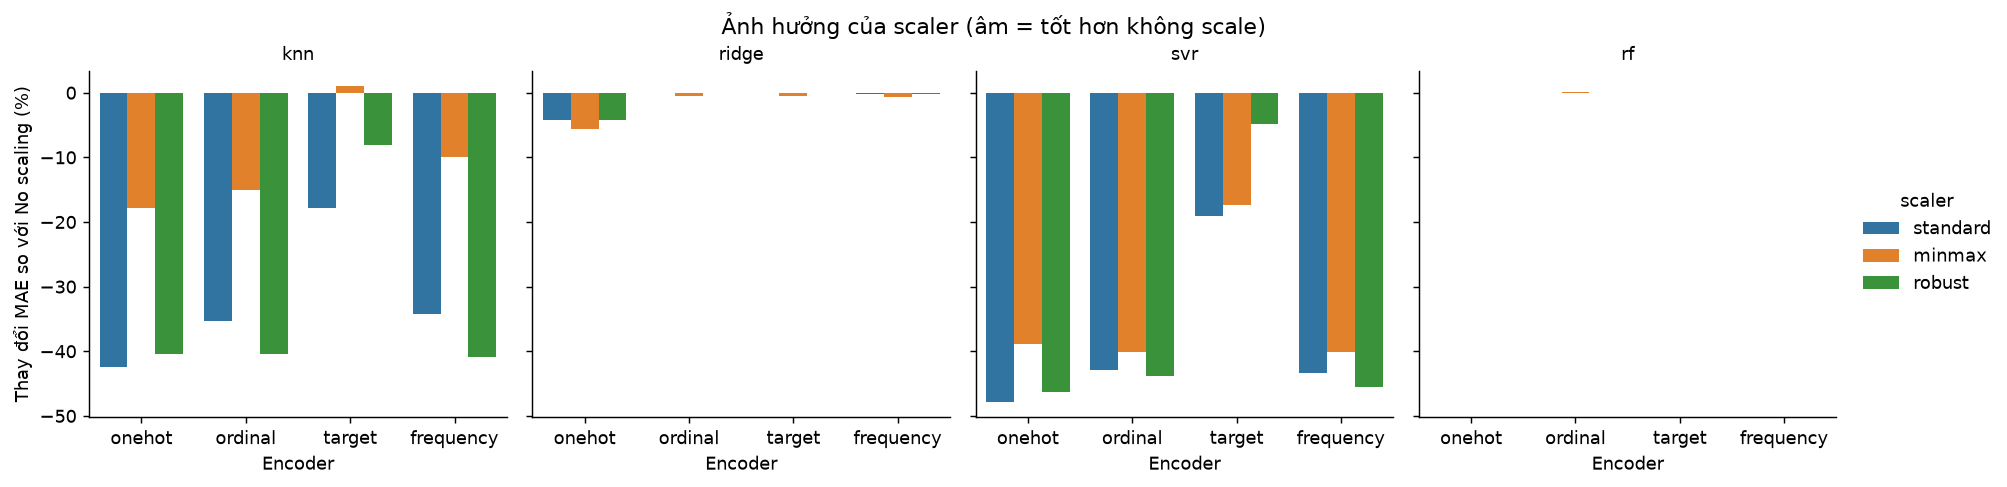

In [7]:
display(Image(str(F / 'week2_scaler_effect.png')))

## 4. Log transformation của giá (thí nghiệm riêng)

,model,encoder,a_mean,b_mean,mean_diff,folds_b_better,folds,rel_change_pct
0,knn,frequency,"10,981.70","11,044.77",63.07,3,5,0.57
1,knn,onehot,"9,621.97","9,548.67",-73.30,3,5,-0.76
2,knn,ordinal,"10,739.66","10,631.67",-108.00,3,5,-1.01
3,knn,target,"10,287.82","9,818.46",-469.36,5,5,-4.56
4,rf,frequency,"7,968.42","7,676.44",-291.98,4,5,-3.66
5,rf,onehot,"7,369.14","7,462.88",93.74,3,5,1.27
6,rf,ordinal,"7,675.92","7,563.20",-112.72,4,5,-1.47
7,rf,target,"7,617.44","7,226.39",-391.06,5,5,-5.13
8,ridge,frequency,"23,737.61","14,658.78","-9,078.83",5,5,-38.25
9,ridge,onehot,"23,011.71","9,590.04","-13,421.68",5,5,-58.33


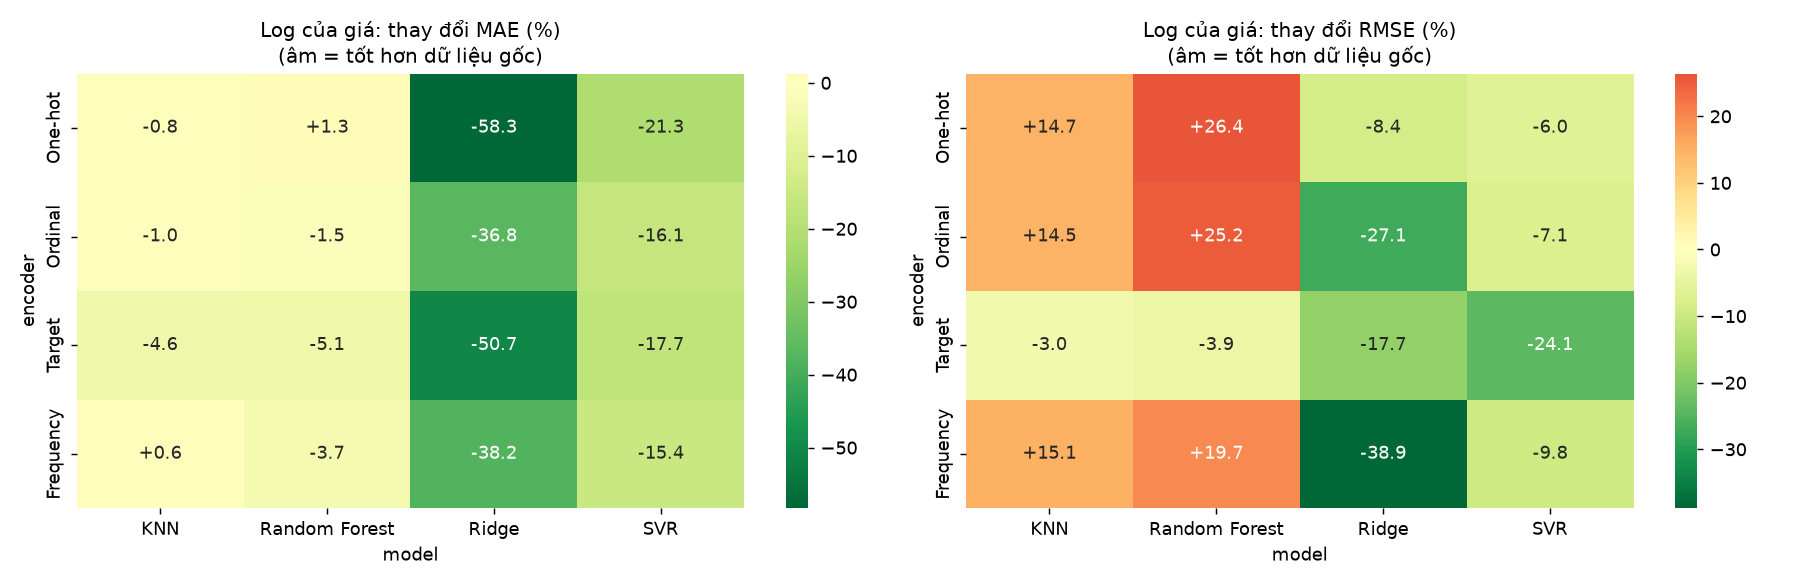

In [8]:
display(pd.read_csv(T / 'week2_log_target_vs_raw_mae.csv'))
display(Image(str(F / 'week2_log_target_effect.png')))

## 4b. Log transformation của biến đầu vào lệch (mileage, power, engine)

,model,encoder,a_mean,b_mean,mean_diff,folds_b_better,folds,rel_change_pct
0,knn,frequency,"10,981.70","12,096.40","1,114.70",0,5,10.15
1,knn,onehot,"9,621.97","10,529.66",907.69,0,5,9.43
2,knn,ordinal,"10,739.66","11,960.70","1,221.03",0,5,11.37
3,knn,target,"10,287.82","10,740.40",452.58,0,5,4.40
4,rf,frequency,"7,968.42","7,951.19",-17.23,4,5,-0.22
5,rf,onehot,"7,369.14","7,396.71",27.57,3,5,0.37
6,rf,ordinal,"7,675.92","7,684.99",9.08,2,5,0.12
7,rf,target,"7,617.44","7,531.19",-86.26,5,5,-1.13
8,ridge,frequency,"23,737.61","22,666.88","-1,070.73",4,5,-4.51
9,ridge,onehot,"23,011.71","20,708.57","-2,303.14",5,5,-10.01


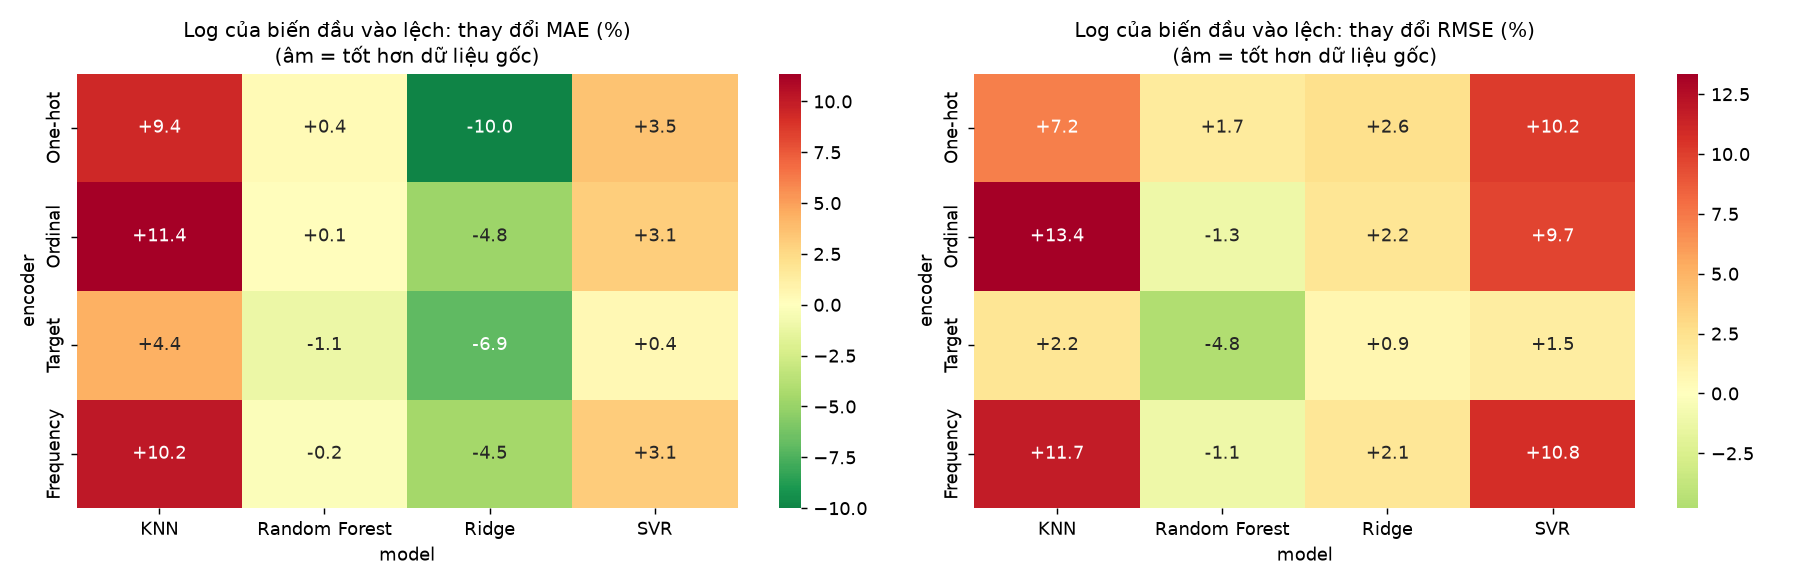

In [9]:
display(pd.read_csv(T / 'week2_log_features_vs_raw_mae.csv'))
display(Image(str(F / 'week2_log_features_effect.png')))

Ridge hưởng lợi, KNN/SVR tệ hơn, Random Forest gần như không đổi (cây bất biến với biến đổi đơn điệu).

## 5. Thêm `model_version` (71 nghìn danh mục)

,model,encoder,a_mean,b_mean,mean_diff,folds_b_better,folds,rel_change_pct
0,knn,frequency,"10,981.70","11,148.74",167.04,0,5,1.52
1,knn,onehot,"9,621.97","9,613.65",-8.32,3,5,-0.09
2,knn,ordinal,"10,739.66","12,062.91","1,323.24",0,5,12.32
3,knn,target,"10,287.82","10,411.42",123.60,0,5,1.20
4,rf,frequency,"7,968.42","7,996.98",28.57,1,5,0.36
5,rf,onehot,"7,369.14","7,367.40",-1.74,4,5,-0.02
6,rf,ordinal,"7,675.92","8,303.14",627.22,0,5,8.17
7,rf,target,"7,617.44","7,584.58",-32.86,4,5,-0.43
8,ridge,frequency,"23,737.61","23,739.93",2.32,0,5,0.01
9,ridge,onehot,"23,011.71","23,018.58",6.87,2,5,0.03


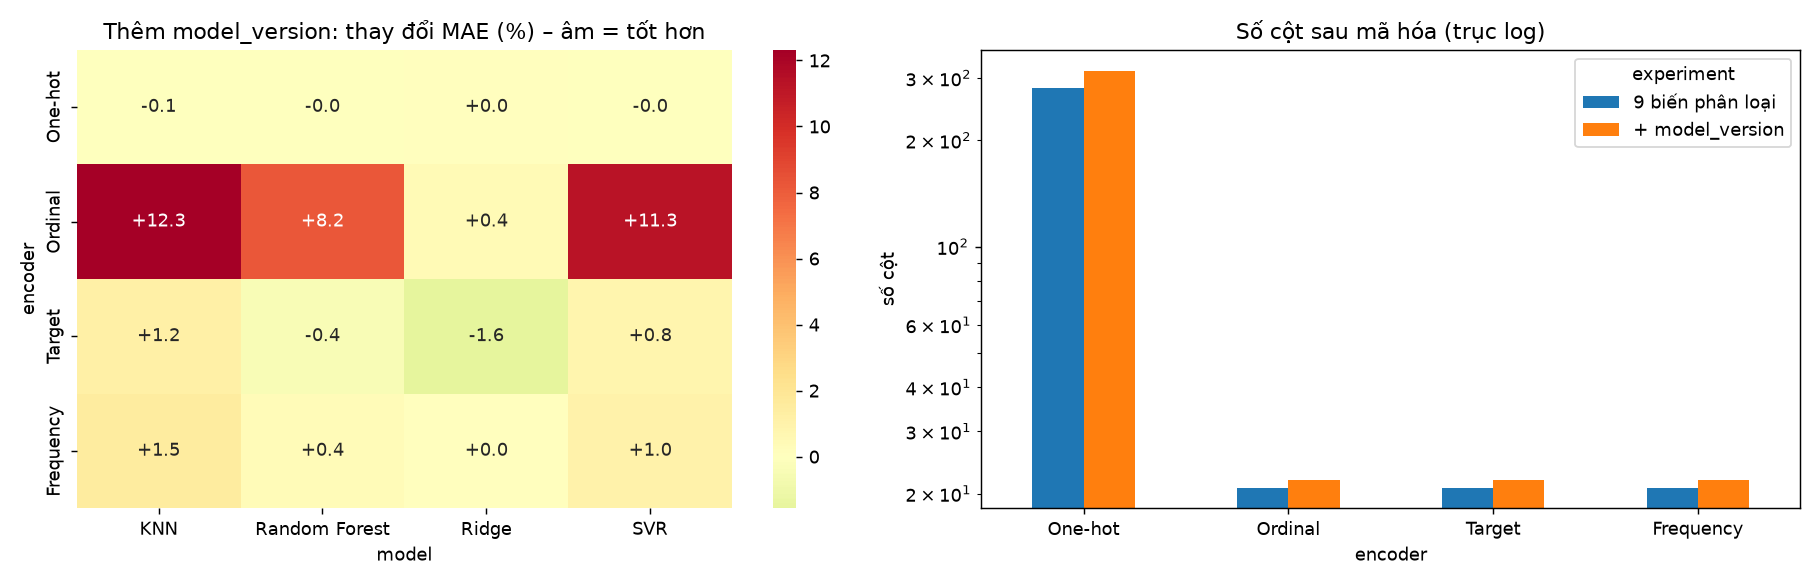

In [10]:
display(pd.read_csv(T / 'week2_model_version_vs_main_mae.csv'))
display(Image(str(F / 'week2_model_version_effect.png')))

## 6. Xác nhận trên toàn bộ train (75.457 dòng; không gồm SVR)

In [11]:
p = T / 'week2_confirm_full_train.csv'
pd.read_csv(p) if p.exists() else print('Chưa chạy: python -m src.experiments --confirm')

,model,encoder,scaler,mae_dev,mae_full,rmse_full,r2_full,medape_full,fit_seconds_full,n_features,folds,rank_dev,rank_full
0,ridge,frequency,minmax,"23,623.73","26,428.22","106,497.74",0.23,46.98,1.37,21,5,4,4
1,knn,frequency,standard,"10,981.70","9,182.16","60,241.38",0.74,11.22,1.35,21,5,4,4
2,rf,frequency,standard,"7,968.42","6,631.28","48,671.17",0.84,7.95,85.98,21,5,4,3
3,ridge,onehot,minmax,"22,681.17","15,740.86","66,248.59",0.70,24.42,1.91,400,5,1,1
4,knn,onehot,standard,"9,621.97","8,079.90","55,364.71",0.78,9.92,1.05,400,5,1,1
5,rf,onehot,standard,"7,369.14","6,276.04","49,383.58",0.83,7.61,"1,162.45",400,5,1,1
6,ridge,ordinal,minmax,"23,366.01","26,012.06","106,980.86",0.22,45.19,0.89,21,5,3,3
7,knn,ordinal,standard,"10,739.66","8,988.05","59,331.13",0.75,10.96,0.70,21,5,3,2
8,rf,ordinal,standard,"7,675.92","6,494.63","51,301.70",0.82,7.69,153.44,21,5,3,2
9,ridge,target,minmax,"22,842.90","23,123.74","86,735.72",0.47,39.85,1.01,21,5,2,2


## 7. Kết luận ngắn
- Random Forest cho MAE thấp nhất; SVR và KNN ở giữa (gần nhau); Ridge kém nhất với giá gốc.
- **Scaling** quyết định kết quả của KNN và SVR, không ảnh hưởng Random Forest, ảnh hưởng nhỏ lên Ridge.
- **One-hot** tốt hơn Ordinal/Frequency ở KNN, SVR, Random Forest nhưng tốn nhiều cột và thời gian hơn. Với Ridge, tập con 20k không phân biệt rõ các encoder, nhưng trên toàn train One-hot vượt rõ rệt (mục 6).
- **Log giá** giúp Ridge/SVR rất nhiều nhưng có thể làm RMSE của KNN/Random Forest tệ hơn; **log biến đầu vào** chỉ giúp Ridge, làm KNN/SVR tệ hơn.
- Siêu tham số chưa tinh chỉnh; tập test chưa dùng (việc của tuần 3).